# E99: Does the reuse definition read right where the answer is known, and what does it say on the old tasks?

**The answer.** Under the refined rules, only the copying task gets a verdict on the 67M model. Its gain runs through two copying heads, and fine-tunes forced through those heads or kept away from them read as built. Every other old task reads "does not apply", "no capability listed", "no admissible capability" or "unreadable", each with its reason. The class map fails the new admissibility test: removing the class costs a hand-built reader of the input more than its band, so removing value directions has no admissible site here.

*Status: provisional, no independent check. Full record: `reports/analyses/2026-11-05_analysis_e99-definition-verify.md`. A new circuit built from old parts still reads as reuse, on every claim below.*


## What we were trying to test

Our definition of reuse says an update reuses a capability when its behaviour runs through what that capability computes, read by removing it. Since the user's decision of 2026-11-05, a label needs a located mechanism. E97 located two pairs of attention heads in the 67M model: heads (2,3) and (2,4) carry the copy fine-tune's gain, and heads (1,1) and (1,2) matter on the lowercase task.

Fable proposed reading a located pair through the **net share**. Switch the pair off, by setting its outputs to the original model's mean over the same inputs, in both the fine-tuned model and the original model. Then

$$\text{net} = \frac{\text{fine-tune's drop} - \text{original model's drop}}{G},$$

where $G$ is the fine-tune's mean gain in the log-odds of its target. A net share of 1 means the whole gain vanishes with the pair, 0 means none of it does, and a negative value means the gain is larger with the pair off. Each state's **band** is the 95th percentile of the absolute net share over 20 random head pairs outside the pair.

To test the quantity we need fine-tunes whose answer is known by construction:

- **Forced**: only the pair's query, key and value weights may move; everything else is reset to the original model after every step. Switching the pair off then leaves exactly the original model with the pair off, so the net share must be 1. This is the positive control.
- **Forbidden**: train with the pair held at its mean and its weights frozen, then read with the pair restored. The update never used the pair, so the net share should sit inside the band.

Each arm trains until its gain, read on a check subset in its training condition, is within 2% of the native fine-tune's, capped at ten times the native's steps. Copy uses E62's recipe and windows, 30 native steps, with E62's lookup fine-tune as the control that should be spared. Lowercase uses E53's recipe on whole rows, 300 native steps, with E53's cipher fine-tune as its control. Two seeds each.

A first stage checks the apparatus: the original model's drops must reproduce E97's. It also tests a proposed admissibility clause: the lowercase pair must change the original model's case leaning on cased rows, which the lowercase task never trained on.


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/definition_verify/figures")


## What we expected, and why

The first stage should reproduce E97 to the digit, since the code and inputs are the same, and the lookup fine-tune should lose nothing at the copying pair. The lowercase pair was expected to move the case leaning on cased rows; the coded rule also asked for a move on lowercased rows, which the plan did not.

Both forced arms should read 1 within 0.05, whether or not they reach the native gain. The filing says what failing to reach it means on lowercase: the net share then has no positive control there, and lowercase falls back to "does not apply". Both forbidden arms should read inside their band. On copy the gain with the pair restored should be within 10% of the native's; on lowercase the arm should learn as fast as the native.

## What we observed

### Does the lowercase pair change the original model's case leaning on text it was never trained on?


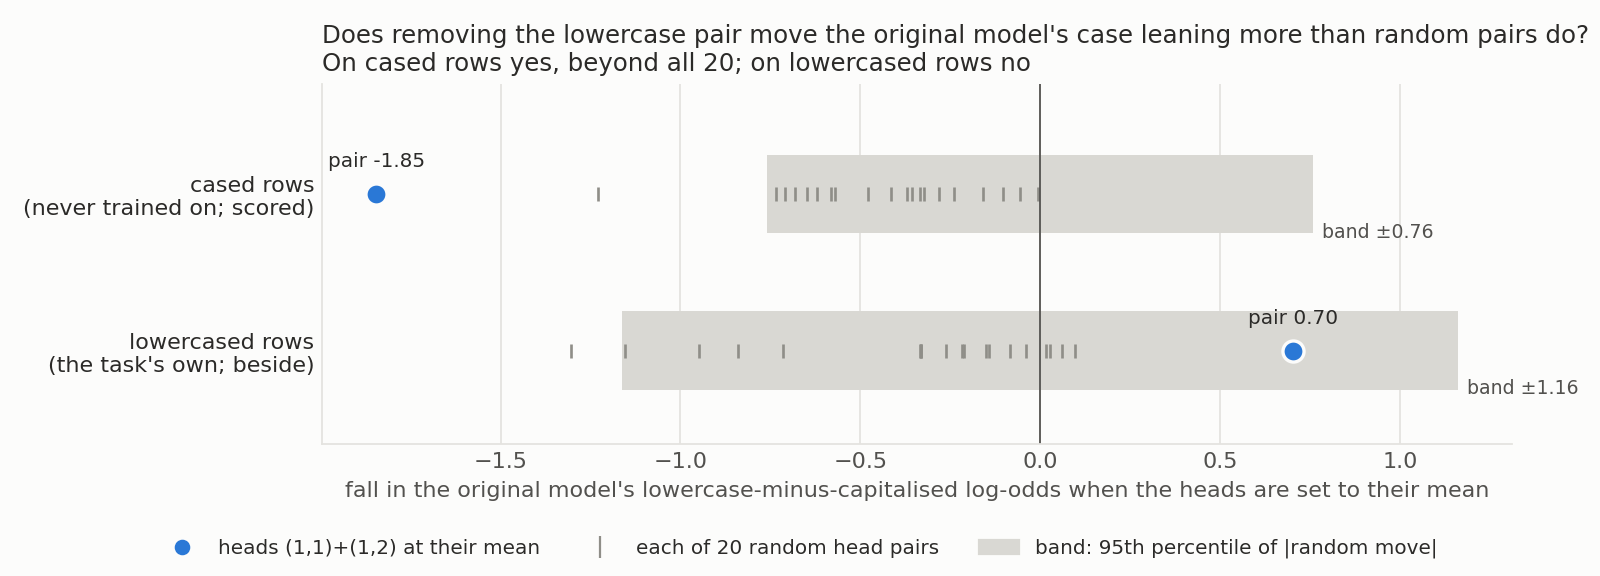

In [2]:
display(Image(FIG / "clause_ii.png", width=950))


**Reading it.** On cased rows yes; on lowercased rows it cannot be told from random pairs. Switching the pair off moves the case leaning on cased rows by -1.85, beyond the band of 0.76 and beyond every random pair. On lowercased rows it moves by 0.70, inside a band of 1.16. The coded rule asked for both, so it missed and the lowercase arms were skipped. Amendment 1, filed before running, scored the plan's wording, cased rows only; that passed, and the lowercase arms ran in a second job. The caveat: every random pair also moves the cased-row leaning in the same direction. The clause shows the pair matters more than a random pair to this one gap, not that it does something specific to case.

### How much of each fine-tune's gain disappears with the pair off?


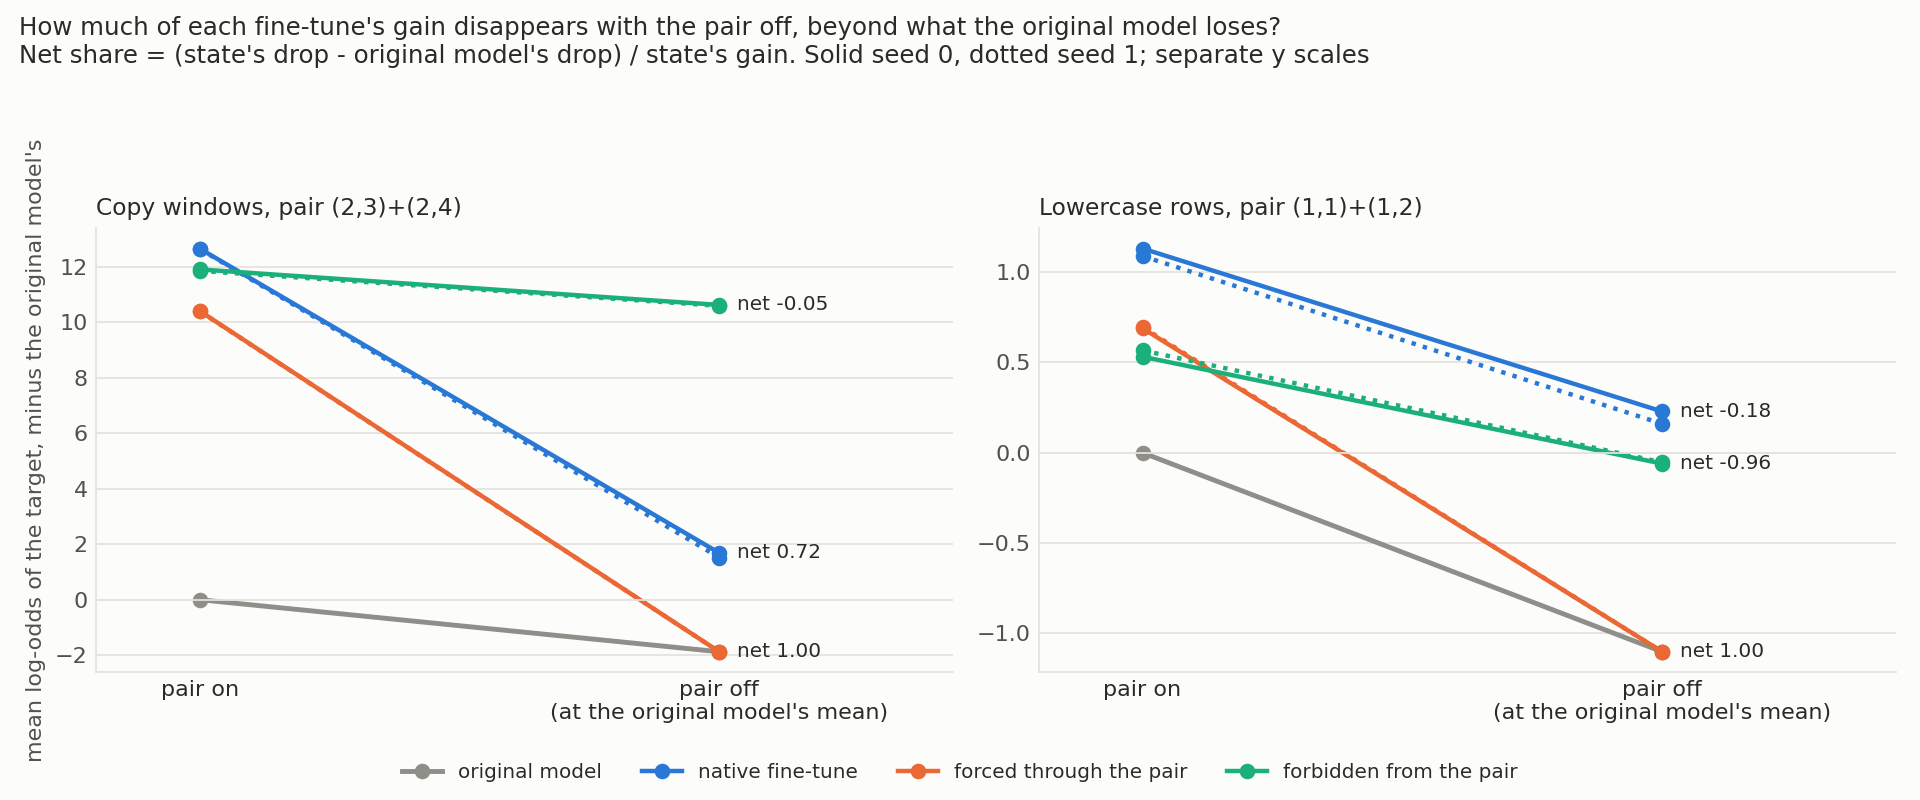

In [3]:
display(Image(FIG / "on_off.png", width=1000))


**Reading it.** On copy the three fine-tunes separate cleanly. The forced fine-tune falls to exactly where the original model falls, net 1. The native falls most of the way, net 0.72. The forbidden fine-tune barely moves, net -0.05. On lowercase the forced fine-tune also lands on the original model, net 1, but it started only 0.69 above it, against the native's 1.13. The forbidden lowercase fine-tune's line is the anomaly: with the pair on it sits 0.53 above the original model, and with the pair off 0.06 below it.

### Do the forced and forbidden fine-tunes read 1 and about 0, against each state's band?


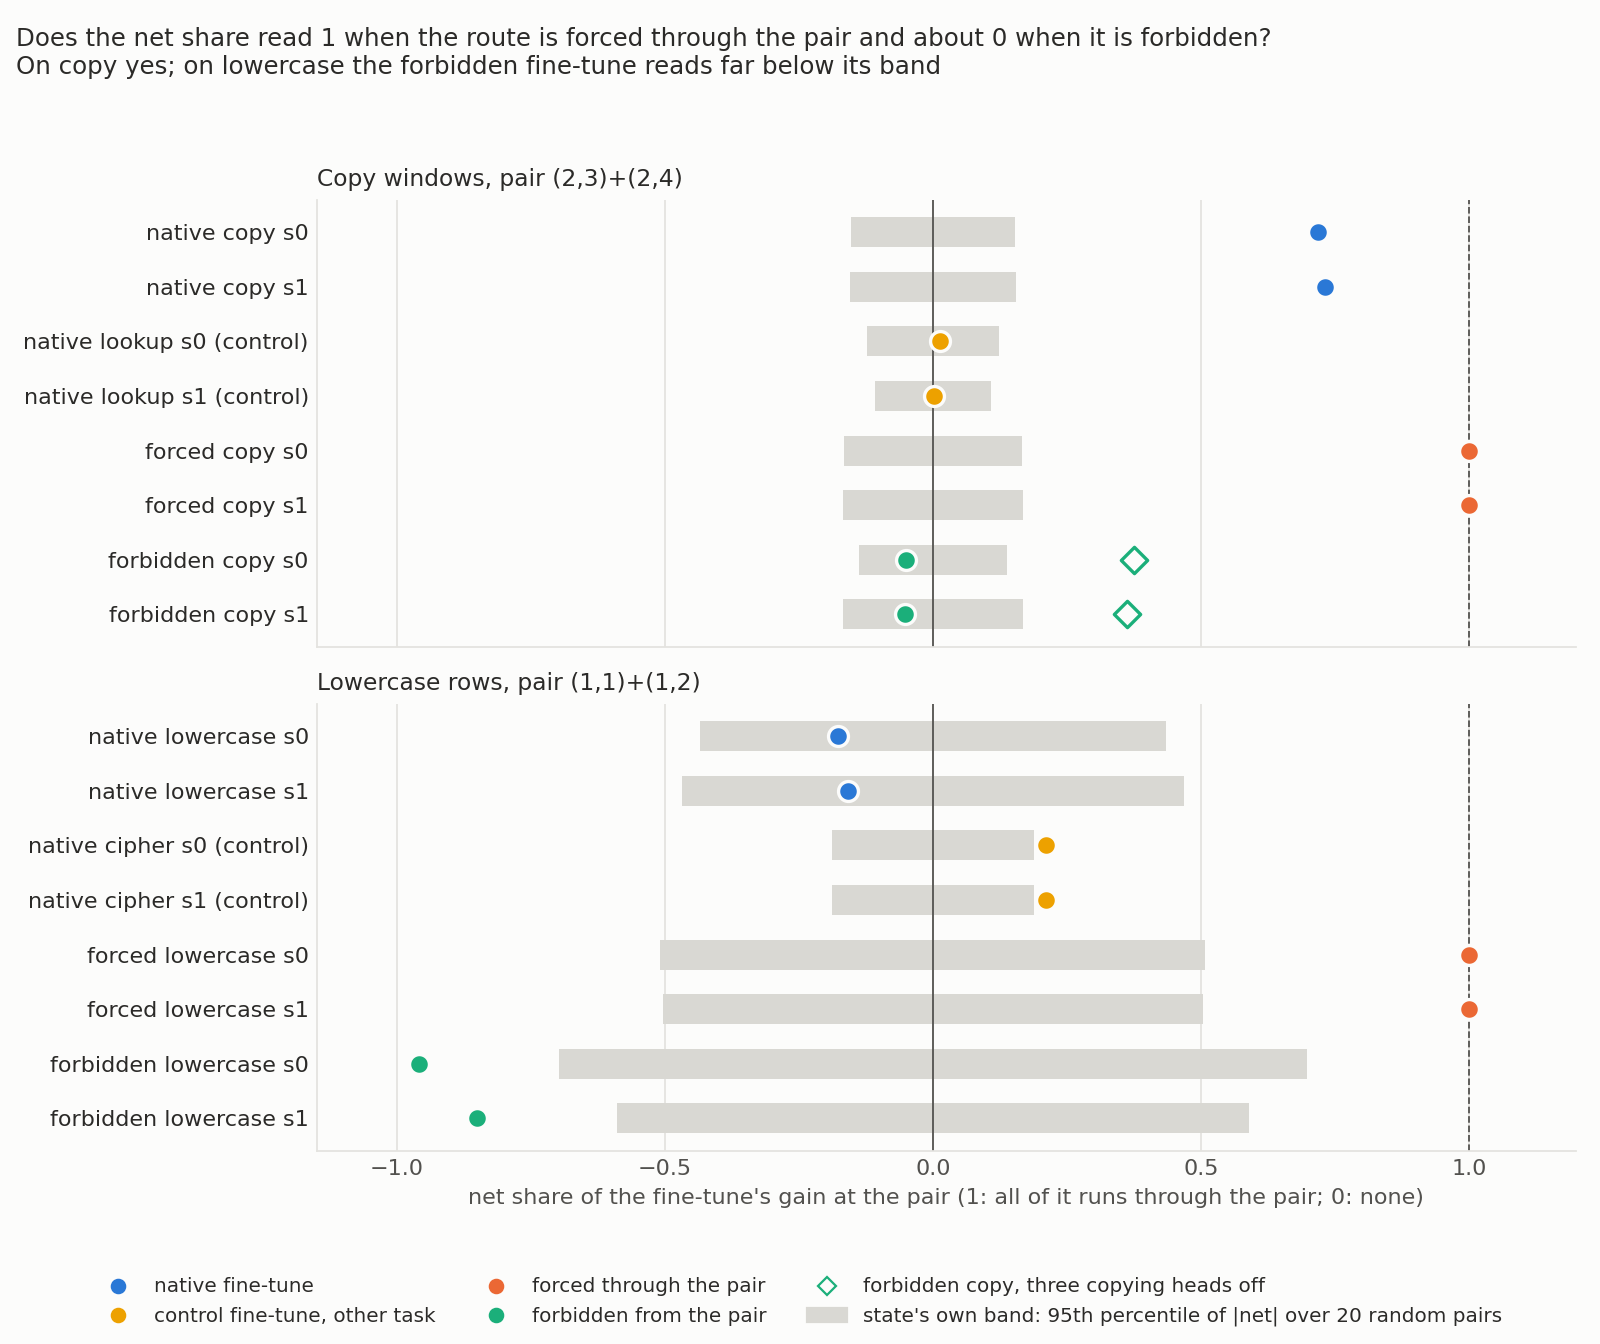

In [4]:
display(Image(FIG / "net_share.png", width=900))


**Reading it.** On copy yes, on both seeds; on lowercase only the forced half does. Forced reads 1.00 on both tasks. Forbidden copy reads -0.05 against bands of 0.14 and 0.17, and keeps 0.94 of the native gain with the pair restored. With head (3,4) also off, the third copying head E62 found, forbidden copy loses about 0.37 net: part of its route moved to a neighbouring copying head. No band was drawn for that set, so it is a reading beside. Forbidden lowercase reads -0.96 and -0.85, far below bands of 0.70 and 0.59. The cipher control at the lowercase pair reads 0.21 net, just above its band of 0.19.

### Why does forbidden lowercase read far below its band?

The figure of each model with the pair on and off shows it. The arm's stop rule compared its gain, read with the pair off and against the original model with the pair off, to the native's gain, read against the intact original model. On lowercase, switching the pair off costs the original model 1.10, about the whole target of 1.15. After five steps the arm had made up that cost: with the pair off it sits 0.06 below the intact original model, and the check read past the target, so training stopped. The training loss on the same first batch shows the deficit it started from: 4.05 with the pair off against 3.31 with it on. On copy the same cost is 1.88 against a target of 12.6, so the forbidden copy arm was barely affected.

The restored model is not worse than the ablated one; putting the pair back raises it by 0.59. That is about half of what the pair gives the original model, 1.10. So the update raises the target by 1.04 with the pair off in both models, and by only 0.53 with it on. That is what a net share of -0.96 says: what the update adds does not stack on top of what the pair does. Why not is unmeasured, and whether an arm trained to the native gain would also read below band was not run.

### Can a fine-tune reach the native gain through the pair alone?


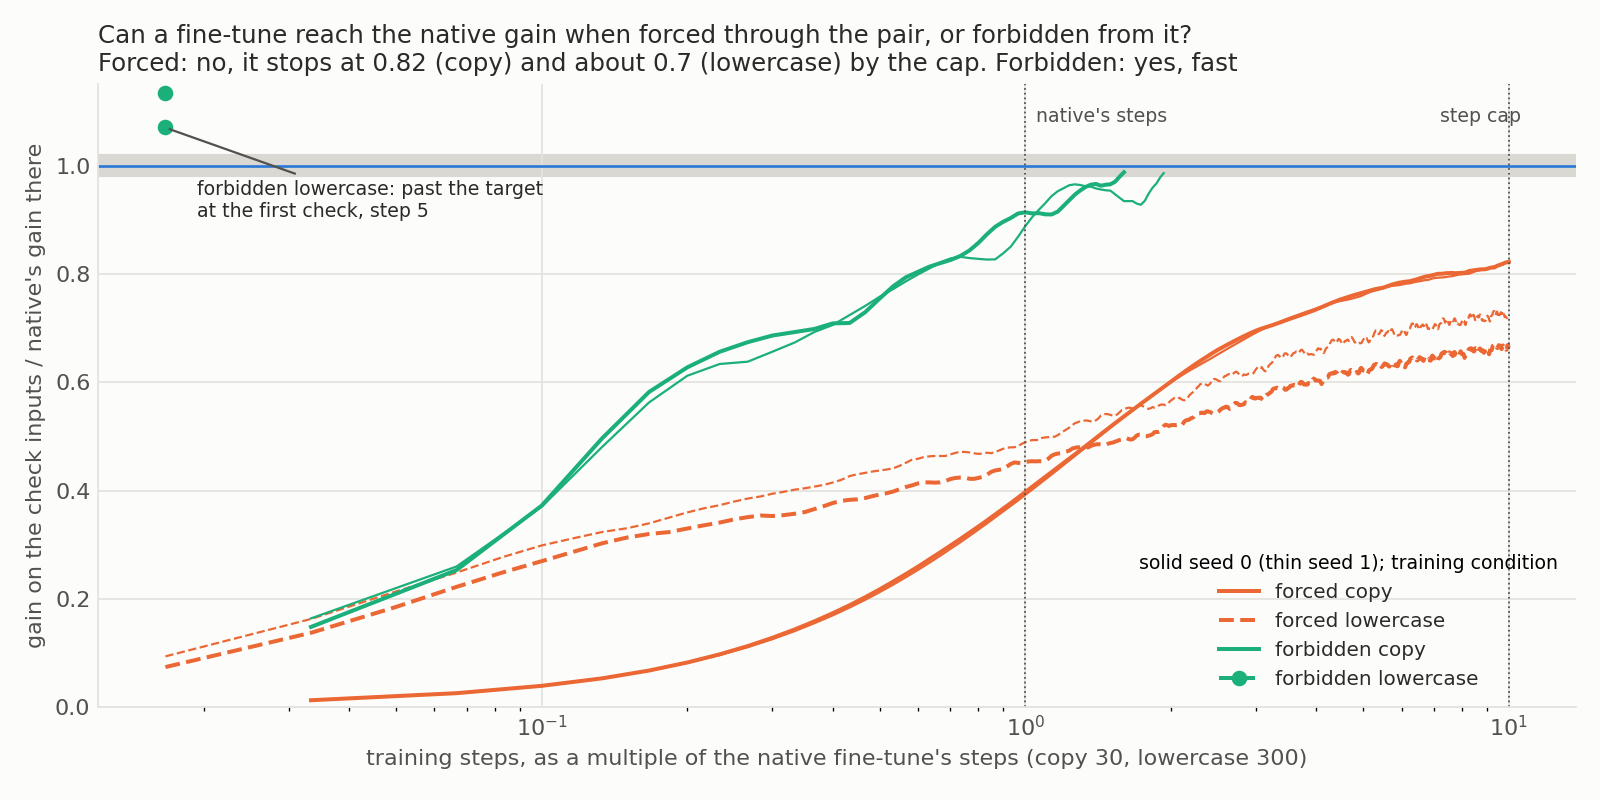

In [5]:
display(Image(FIG / "gain_curves.png", width=950))


**Reading it.** No, on either task. Limited to the two heads' query, key and value weights, the copy fine-tune reaches 0.82 of the native gain by the cap of 300 steps, still rising slowly. The lowercase fine-tune reaches 0.61 and 0.64 on whole rows by 3,000 steps, its curve nearly flat. On copy this does not touch the filed rule. On lowercase the filing reads it as no positive control, and lowercase stays "does not apply". The forbidden copy arm reaches the native gain in 48 and 58 steps.


## Stages 4 and 5: every old task under the refined rules

Stage 4 reads every old 67M task again under three rules the plan adopted from Fable.

- The **net-share rule** above, now giving a verdict only where the forced arm read 1 and the forbidden arm read inside its band. On the copying pair both held.
- An **admissibility rule**, checked before any band. The capability must merge inputs: at least two inputs per value on average. And a hand-built reader of the input alone, placed downstream of the removal, must stay inside its own band when the capability is removed. If that reader loses its gain, the removal deletes the input, and a state's loss shows no more than that the state needs its input.
- **Per-state bands**: each state gets its own band from 20 random removals matched in variance. Two states are compared with E95's paired test, which asks whether the gap between their losses beats the same gap under every random removal.

Most of this reads numbers already stored. The new run rebuilds E58's class map and its shuffled twin, two seeds each. The class map sends each of 96 keys to one of four words, and a key's class is fixed by where its input embedding sits in the original model. The twin learns the same words with the classes shuffled. The capability is this embedding class, removed at block 1. A hand-written change upstream of the removal, writing each key's answer, should be spared. The same change placed downstream is the admissibility reader.

We expected the copy verdict to stand, the copy maps to close on the admissibility rule, and every per-state verdict to read as written down from the stored numbers. For the class map we leaned, at 60%, towards the reader failing. If it fails, removing value directions has no admissible site on this model.

### Which old states lose more of their gain than their own random band?


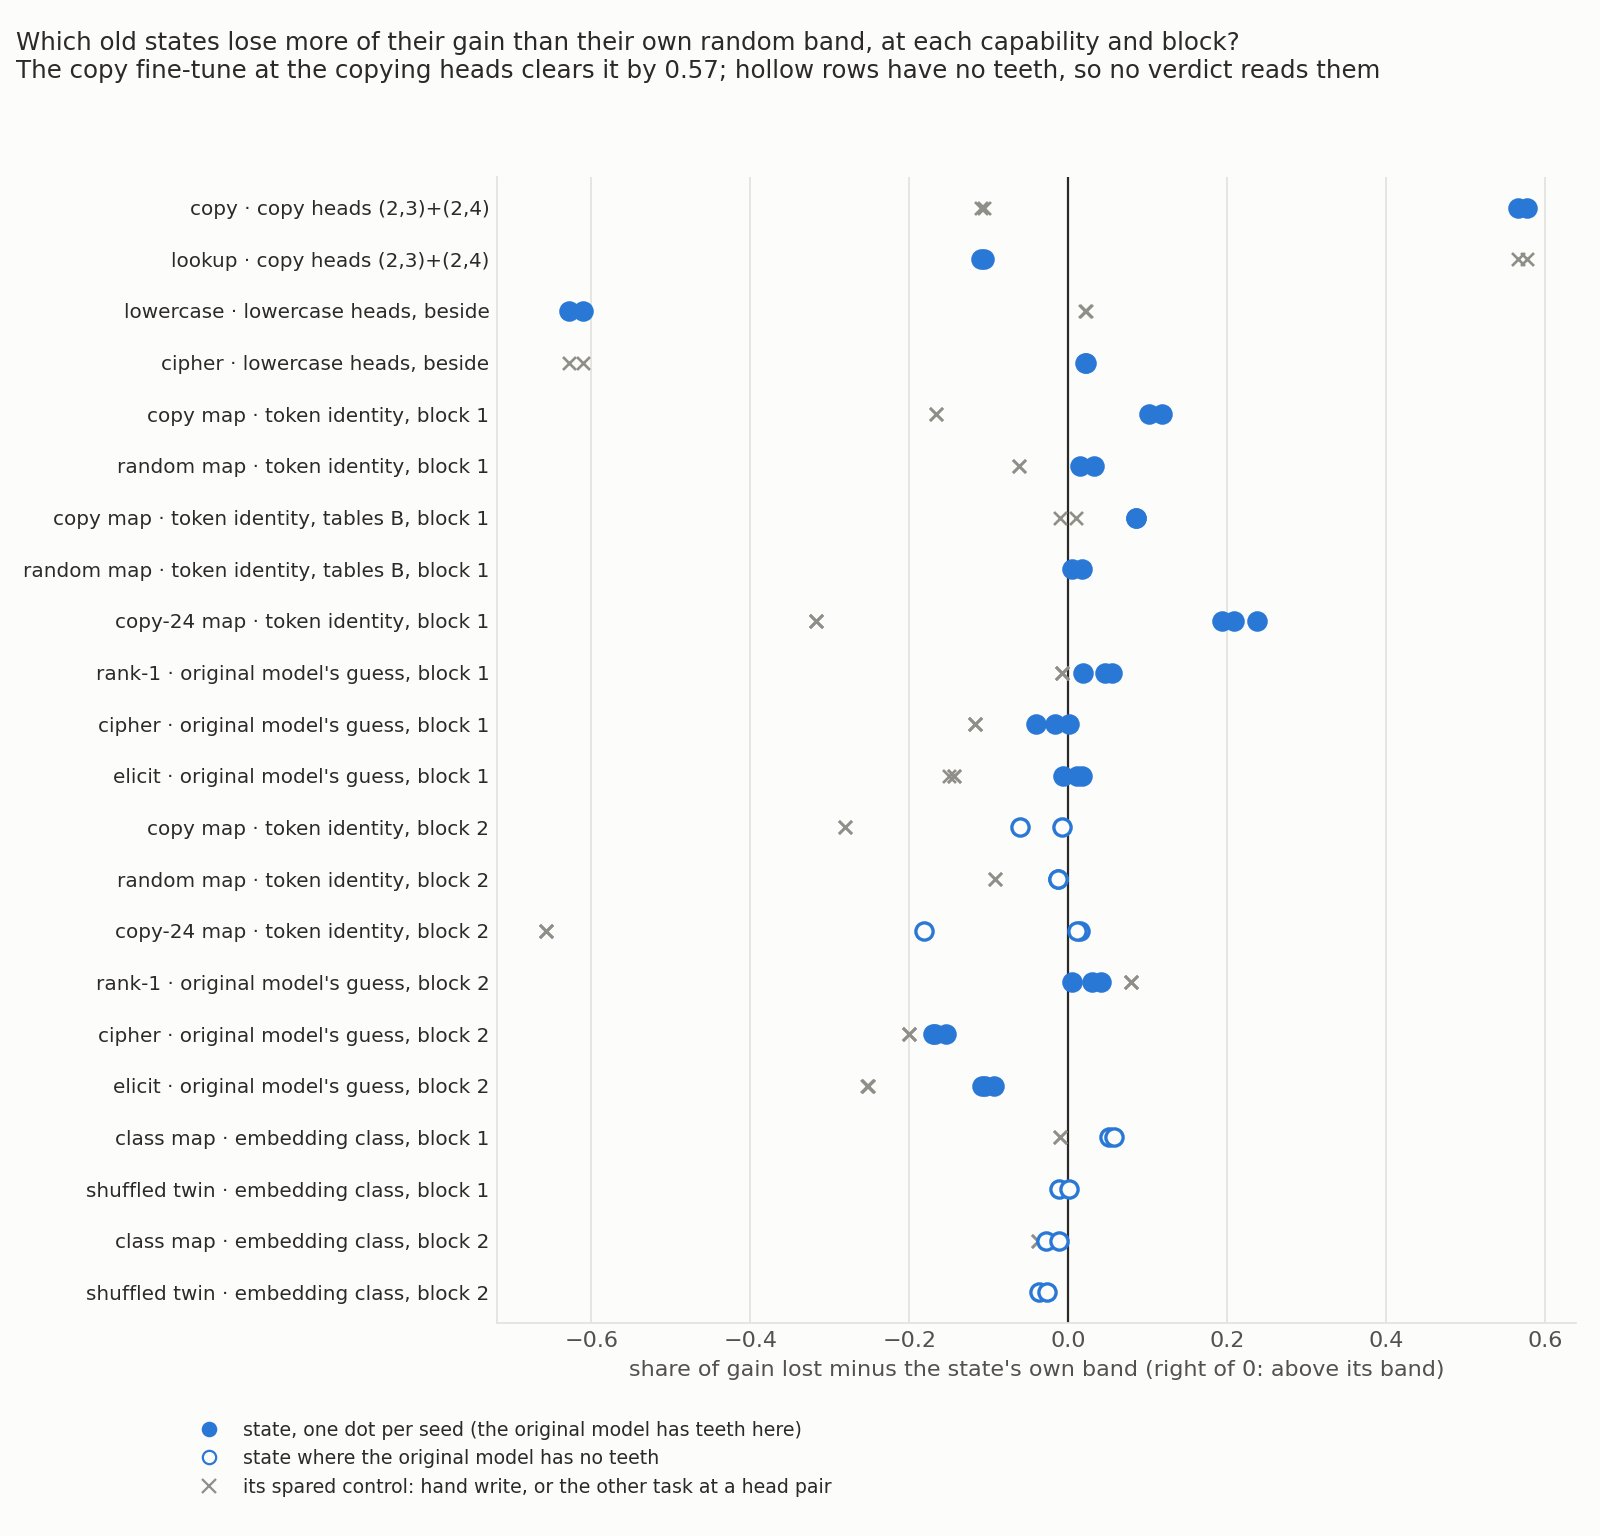

In [6]:
display(Image(FIG / "bands.png", width=950))

**Reading it.** Only the copy fine-tune clears its band by far, and it now does so with its controls. At the copying heads it sits 0.57 above its own band on both seeds, while lookup sits inside its band. Every other state sits within about 0.25 of its band, and every per-state verdict reads as written down before the run; no band needed pooling. The copy maps at token identity also clear their bands, but the next figure closes those sites before any band is read. Hollow rows are sites where the original model itself loses no more than under random removals, so no verdict reads them.

Two paired comparisons differ from the filing, and no verdict reads either. At token identity, block 2, the copy map loses less than the random map. The random gaps are more negative still, so three of four seed pairs read as separated, where none was filed. At the original model's guess, block 2, rank-1 against cipher separates on every seed pair where some was the lean.

### Does removing the capability delete the input?


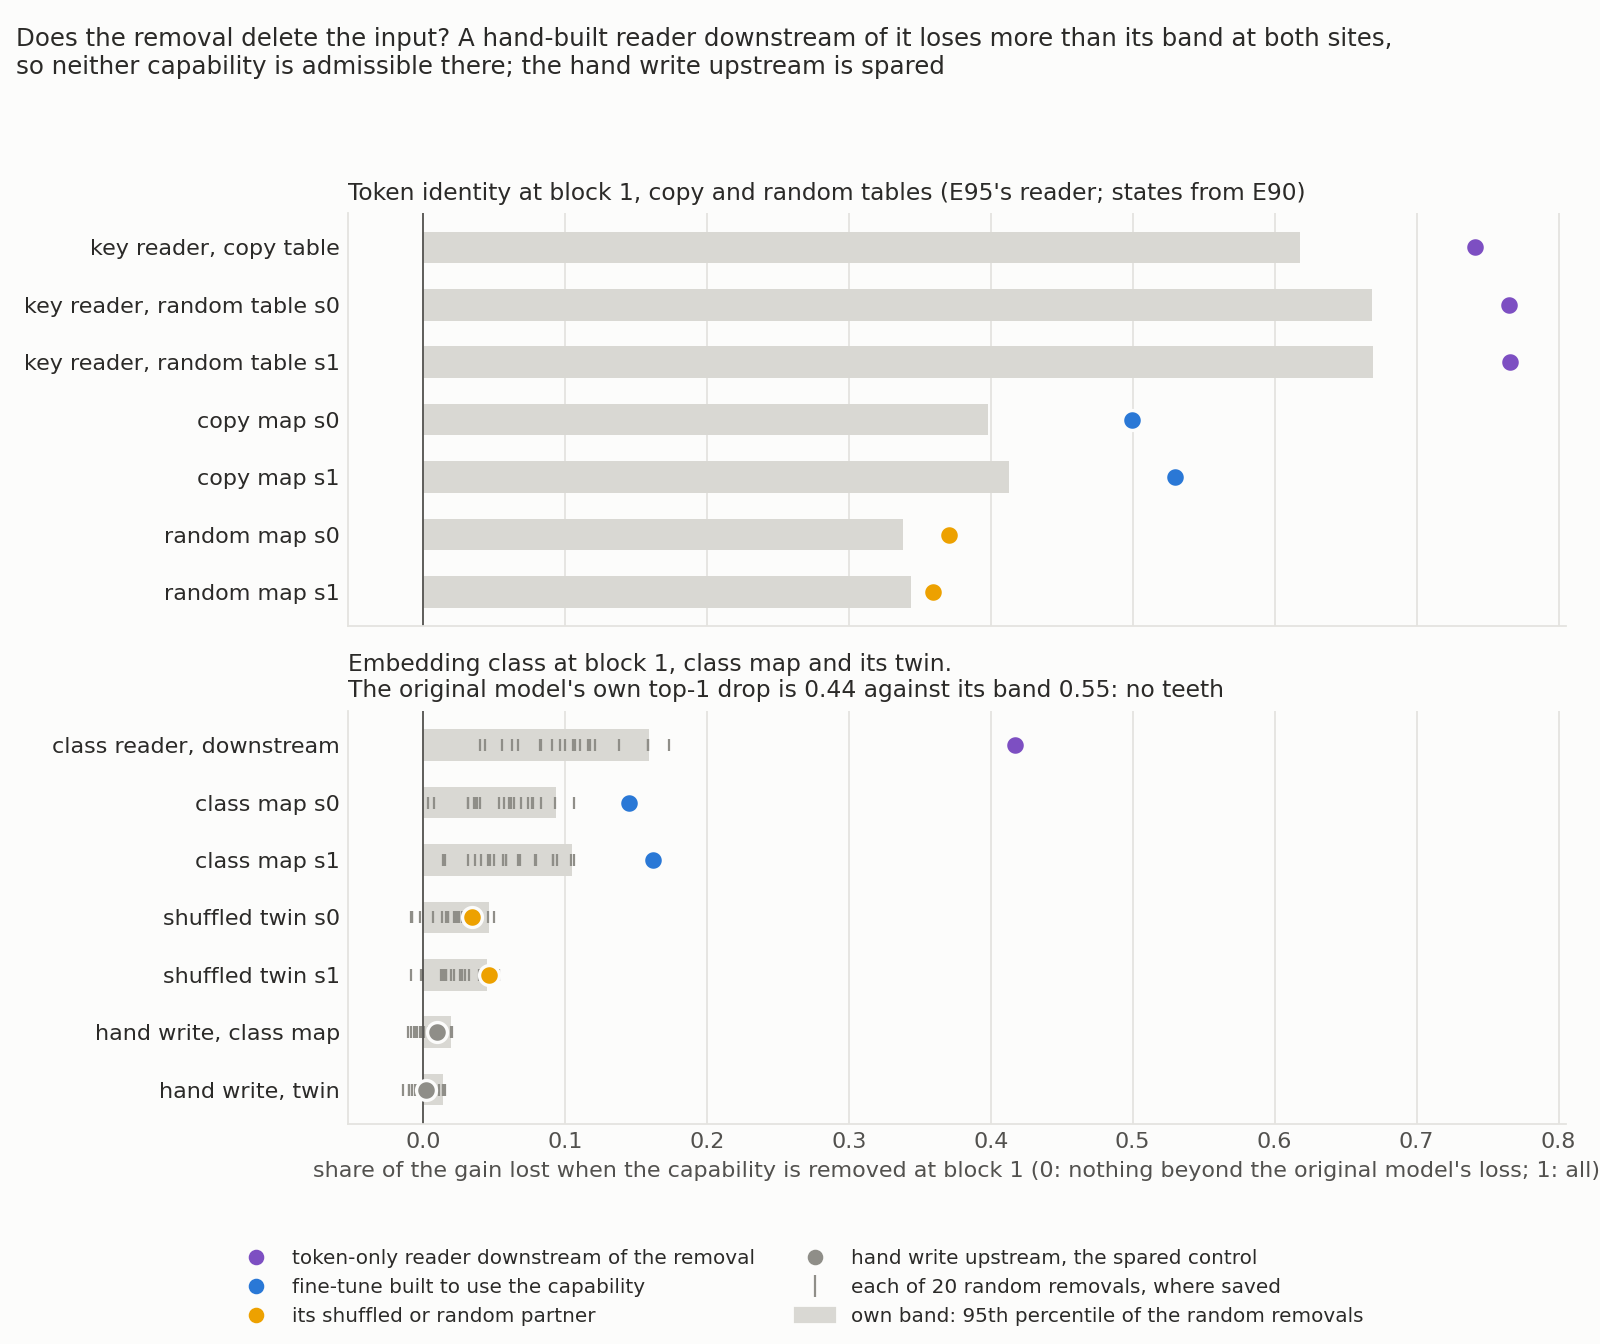

In [7]:
display(Image(FIG / "class_map.png", width=950))

**Reading it.** Yes, at both sites where a reader was placed. Under token identity, E95's hand-built key reader loses about three quarters of its gain, above its band and more than any fine-tune. Under the embedding class, the same kind of reader at block 2 loses 0.42 of its gain against a band of 0.16. That is more than either class-map fine-tune loses. So both capabilities fail the admissibility rule, and the class map reads "no admissible capability at this site: the removal deletes the input". The hand write upstream is spared on both tables, as the control requires.

Even if the class were admissible, this site could not give a verdict. The original model's own next token falls 0.44 under the class removal, against 0.55 for random removals, so the removal has no teeth there. Beside the verdict: the class-map fine-tunes lose more than their own bands and more than the twin on every seed pair. That is a real difference of degree, but it shows no more than the copy map's lead under token identity did, since the reader of the input itself loses more. Both rebuilt fine-tunes reproduce E58's held-out probability to four decimals.

### One table of every old task

| Task | Assumed | Verdict | Reason |
|---|---|---|---|
| Copy | reuses | **reuses C** | gain runs through heads (2,3) and (2,4); forced and forbidden arms read as built; lookup spared |
| 32-key copy map, both table pairs; 24-key copy map | strengthens or reuses | no admissible C | token identity has one key per value; where read, the key reader loses more than its band |
| Class map | a new rule that carries | no admissible C | the class reader loses 0.42 against 0.16; no teeth either way |
| Rank-1 | old | unreadable | no token-only reader was placed downstream, so the second clause is not read |
| Lookup, random maps, ciphers, elicit, twin, shuffled elicit | new or half-known | no C listed | no capability passes E90's admissibility; elicit passes on one parity split of two |
| Lowercase | reuses | does not apply | constant answer; the net share has no positive control on its heads |
| Emoticon, ladder rungs, many-to-one, single random key | existing or new | does not apply | constant answer, E90 |
| Input-dependent ladder, emoticon, lowercase; ladder push | existing | unreadable or no version kept the target | E90, unchanged |

Every row reads as filed. The full table, with E90's remaining rows and every number, is in the report.


## What we learned

The net share passes both of its tests on the copying pair. So copy against lookup carries the verdict "reuses C" as a reading, not an assumption, with the granularity limit beside it. On the lowercase pair the forced fine-tune cannot reach the native gain, so the quantity has no positive control there, and fixed-answer tasks stay "does not apply".

Stage 4 closes every other old row with a reason. Token identity is never an admissible capability at a copy-map site. The embedding class merges inputs but its removal deletes what a reader of the input needs. The class map was the one old task whose capability is neither its answer nor its input token, so removing value directions has no admissible site on this model. The user's batch decision of 2026-11-05 holds: only the copying pair qualifies for a label.

On the granularity limit: a circuit built from old parts reads as reuse. The one verdict left, on copy, carries that limit. The class map, built to test a new rule over old parts, cannot be read at all. So the 67M offers no case where the definition tells a new circuit of old parts from reuse.

## How compelling is the evidence

Two seeds per arm, one model; the rebuilt class map has two of E58's three seeds. Each band comes from one draw of 20 random removals, so it is about as uncertain as its largest draw. The net share cannot see a new function built inside the pair, or rerouting through other copying heads. The forced arm's 1 is true by construction. The class removal's random draws carry about a sixth less variance than the class directions on the task windows. So part of any excess over a band may be size; the reader's loss is 2.6 times its band. The admissibility reader is one hand-built change at one block; where none was placed, a row reads "unreadable", not a pass.

## Surprises

- **Something we did not predict: the forbidden lowercase fine-tune reads far below its band**, where within band was filed. The stop rule ended its training at step 5, with half the native gain once the pair is restored.
- Both forced arms stop short of the native gain.
- On cased rows every random pair moves the case leaning in the same direction as the lowercase pair.
- Forbidden copy partly moved to head (3,4), as Fable warned it might.
- Stage 4: one firm paired call missed, at token identity block 2, and one lean, at the guess's block 2. No verdict reads either.
- Stage 4: the class-map fine-tunes lose more than their bands under the class removal, while the original model's own next token does not.

## What next

1. Propose the rule changes listed below to the user in one batch. With them, the 67M table stands as read.
2. If removing value directions is still wanted on this model, it needs a capability that merges inputs and whose removal spares a reader of the input. No old 67M task offers one; a reader inside its band at a site where a fine-tune is above its band would change that.
3. If a lowercase reading is still wanted, a forbidden arm stopped against the intact original model would say whether the below-band reading survives at the native gain.


## Scorecard

| Id | Claim | Rule | Read | Verdict |
|---|---|---|---|---|
| S0 | Controls reproduce E97; lookup spared | E97 within row SE; lookup net at most 0.2 | exact; 0.014, 0.003 | held |
| S0-ii | Pair moves case gap on cased and lowercased rows | above band on both | -1.85 vs 0.76; 0.70 vs 1.16 | missed as coded |
| S0-ii-A1 | Same, cased rows only | above band | -1.85 vs 0.76 | held |
| P1 | Forced copy net 1 | within 0.05 | 1.00, 1.00; cap 0.82 | held |
| P2 | Forbidden copy within band; restored within 10% | band; 10% | -0.05, -0.05; 0.94 | held |
| P3 | Forced lowercase net 1, matched or cap | within 0.05 | 1.00, 1.00; cap 0.61, 0.64 | held; cap: falls back to "does not apply" |
| P4 | Forbidden lowercase within band, as fast | band; pace | -0.96, -0.85; step 5 | missed: below band; pace held |
| 4a | Copy "reuses C", lookup spared, every pair | net-share verdict; paired | 0.72, 0.73 vs 0.15; lookup 0.01, 0.00 | held |
| 4b | Copy maps "no admissible C"; rank-1 "unreadable" | admissibility | key reader 0.74-0.77 vs 0.62-0.67 | held |
| 4c | Per-state verdicts as listed, none pooled | own bands | all as listed | held |
| 4c-p | Paired: identity block 2 "no pair" | paired test | some pairs, 3 of 4 | **missed**, read by no verdict |
| 4c-p | Paired: guess block 2 rank-1 minus cipher, lean some | paired test | every pair | lean missed, read by no verdict |
| 4d-r | Class-map fine-tunes reproduce E58 | within 0.02 | equal to 4 decimals | held |
| 4d-t | No teeth at blocks 1 and 2, lean | own top-1 vs band | 0.44 vs 0.55; 0.45 vs 0.78 | held |
| 4d-c | Hand writes spared | within band; over 0.2 stops | 0.010 vs 0.020; 0.002 vs 0.014 | held |
| 4d-b | Reader fails, lean; class map "no admissible C" | admissibility | 0.42 vs 0.16 | held |
| 4d-p | Class map minus twin, every pair, lean | paired test | every pair | held |
| 5 | The one table as listed | `table.py` | every row as listed | held |

Every stage-4 row with its numbers is in the report's scorecard.

## Rule changes proposed to the user

1. The net-share rule for a located part, with its two clauses: removing the part costs the original model its own leaning above the band, and the part's function depends on the input. A verdict needs a forced arm reading 1 and a forbidden arm within band.
2. The lowercase fallback: no forced arm at the native gain means no positive control, so the task stays "does not apply".
3. The input-dependence clause on cased rows only.
4. The admissibility rule, before any band: the capability merges inputs, and a token-only reader downstream stays within its band; not read means "unreadable".
5. Per-state bands, with E95's paired test between states; pooled only if a band's redraw spread exceeds the gap between bands.
6. The code writer's choices, as rules. An input is what the capability's map is a function of. The pooling clause's gap and spread are as filed. The hand-write control is the block-1 write of the state's own table, and a share above 0.2 stops the run. At a head pair the constructed arms stand in for teeth.

## Not run

- The hand-write control at the head pairs; forced-part lookup, which would put a number on the granularity limit.
- A real second set of random removals for any band.
- A token-only reader on the guess rows, tables B or the 24-key keys; any reader at another block.
- E58's third seed of the class map and twin.
- A forbidden lowercase arm trained to the native gain against the intact original model.
- A band for the three-head copying set; any repurposing read on forced lowercase; an independent check; more seeds.

## Departures from the literature

- Jain et al. 2024 read possession through a linear readout and test reuse with probing, pruning and reverse fine-tuning; we read reuse by ablating a located head pair, as the user decided.
- The net share subtracts the original model's own drop; neither Jain et al. nor E97 does.
- Ablation means come from the site's own inputs, as in E96 and E97, not from a separate reference distribution.
- Ground truth comes from restricting a real fine-tune's update, not from compiled or synthetic-grammar models.
- Recipe: lowercase rows repeat past 300 steps; the gradient clip counts reset entries; forbidden arms train with the pair at its mean.
- The admissibility rule is our own; Jain et al. have no test that a removal spares the input.
- The embedding class is defined from the original model's input embeddings, with no trained readout.
- The class map's reproduction is checked in probability, not gain, because E58 logged probability.

## Provenance

Results `experiments/definition_verify/results/stage{0,1,2}.json`, `stage3_amend1.json`, `run.out`, `stage4_cpu.json`, `stage4_class.json`, `stage4.out`, `table.json`. Jobs 52787 (stages 0-2, 296 s), 52807 (Amendment 1 and stage 3, 704 s) and 52895 (stage 4's class map, about 3 min), MATS `debug`, L40; stage 4's other parts and stage 5 on CPU. $0.
